Welcome to the ultimate Black Jack challenge! Prepare to test your skills against an advanced AI opponent, meticulously trained in the art of Black Jack strategy.

In [ ]:
msg: str = (
    "===================================================\n"
    "  Welcome to the ultimate Black Jack challenge!\n"
    "==================================================="
)

print(msg)

  Welcome to the ultimate Black Jack challenge!


In [ ]:
# import random

# def create_deck():
#     suits = ['Hearts', 'Diamonds', 'Clubs', 'Spades']
#     ranks = ['2', '3', '4', '5', '6', '7', '8', '9', '10',
#              'Jack', 'Queen', 'King', 'Ace']
#     deck = [{'rank': rank, 'suit': suit} for suit in suits for rank in ranks]
#     random.shuffle(deck)
#     return deck

# def get_card_value(card):
#     if card['rank'] in ['Jack', 'Queen', 'King']:
#         return 10
#     elif card['rank'] == 'Ace':
#         return 11  # Ace can be 1 or 11, we'll simplify for now
#     else:
#         return int(card['rank'])

# def calculate_score(hand):
#     score = sum(get_card_value(card) for card in hand)
#     # Basic Ace handling: if score > 21 and there's an Ace,
#     # change Ace from 11 to 1
#     num_aces = sum(1 for card in hand if card['rank'] == 'Ace')
#     while score > 21 and num_aces > 0:
#         score -= 10
#         num_aces -= 1
#     return score



# print("\n--- Starting a new Black Jack game ---")

# deck = create_deck()
# player_hand = []
# dealer_hand = []

# # Deal initial cards
# player_hand.append(deck.pop())
# dealer_hand.append(deck.pop())
# player_hand.append(deck.pop())
# dealer_hand.append(deck.pop())

# print("Player's Hand:")
# for card in player_hand:
#     print(f"  {card['rank']} of {card['suit']}")
# player_score = calculate_score(player_hand)
# print(f"Player's Score: {player_score}")

# print("\nDealer's Hand:")
# print(f"  {dealer_hand[0]['rank']} of {dealer_hand[0]['suit']}")
# print("  [Hidden Card]")

# dealer_score = calculate_score(dealer_hand)

# # For simplicity, we'll show the actual score but in a real game, only the first
# # card's value would be visible
# print(f"Dealer's Visible Score (based on first card): {get_card_value(dealer_hand[0])}")

# print("\n--- End of initial deal ---")

### Project Code
**All** project code must go below this line. Thank you!

# =================================================
# Game Play Section
# =================================================

In [ ]:
# Member 1 - Alexander: Basic Rule Set & Calculate Totals

import random

def create_deck():
    suits = ['Hearts', 'Diamonds', 'Clubs', 'Spades']
    ranks = [
        '2', '3', '4', '5', '6', '7', '8', '9', '10',
        'Jack', 'Queen', 'King', 'Ace'
        ]

    deck = [{'rank': rank, 'suit': suit} for suit in suits for rank in ranks]
    random.shuffle(deck)
    return deck

def get_card_value(card):
    if card['rank'] in ['Jack', 'Queen', 'King']:
        return 10
    elif card['rank'] == 'Ace':
        return 11
    else:
        return int(card['rank'])

def calculate_score(hand):
    score = sum(get_card_value(card) for card in hand)
    num_aces = sum(1 for card in hand if card['rank'] == 'Ace')
    while score > 21 and num_aces > 0:
        score -= 10
        num_aces -= 1
    return score


In [ ]:
# Member 2 - Basma: Player Hit/Stand logic
def player_turn(deck, player_hand):
    while True:
        score = calculate_score(player_hand)
        print(f"Player's current score: {score}")

        if score > 21:
            print("Player busts!")
            break

        choice = input("Would you like to Hit or Stand? ").lower()

        if choice == "hit":
            new_card = deck.pop()
            player_hand.append(new_card)
            print(f"You drew: {new_card['rank']} of {new_card['suit']}")

        elif choice == "stand":
            print("Player stands.")
            break

        else:
            print("Please enter Hit or Stand.")

# Legacy AI turn placeholder (not used by the final gamr).
# The active implementation is ai_player_turn(),
# which uses get_ai_action_v2() for decision-making.
def ai_turn(deck, ai_hand, player_score):
    """Simulates the computer/AI turn decision making."""
    print("\n--- AI's Turn ---")
    while True:
        ai_score = calculate_score(ai_hand)
        print(f"AI's current score: {ai_score}")

        if ai_score > 21:
            print("AI busts!")
            break

        # Standard simple dealer rule: hit on anything less than 17
        if ai_score < 17:
            new_card = deck.pop()
            ai_hand.append(new_card)
            print(f"AI hits and draws: {new_card['rank']} of {new_card['suit']}")
        else:
            print("AI stands.")
            break


In [ ]:
def dealer_turn(deck, dealer_hand):
    """Simulates the dealer's turn by hitting until their score is 17 or higher."""
    print("\n--- Dealer's Turn ---")
    while True:
        dealer_score = calculate_score(dealer_hand)
        print(f"Dealer's current cards:")
        for card in dealer_hand:
            print(f"  {card['rank']} of {card['suit']}")
        print(f"Dealer's current score: {dealer_score}")

        if dealer_score >= 17:
            if dealer_score > 21:
                print("Dealer busts!")
            else:
                print("Dealer stands.")
            break

        # Draw a card
        if not deck:
            print("No cards left in the deck!")
            break
        new_card = deck.pop()
        dealer_hand.append(new_card)
        print(f"Dealer draws: {new_card['rank']} of {new_card['suit']}\n")

    return calculate_score(dealer_hand)

In [ ]:
# Phase 2 - Test Alexander's official dealer function

test_deck = [
    {"rank": "5", "suit": "Clubs"}
]

dealer_test_hand = [
    {"rank": "7", "suit": "Hearts"},
    {"rank": "5", "suit": "Spades"}
]

final_score = dealer_turn(test_deck, dealer_test_hand)

print("Final dealer score:", final_score)
print("Dealer test:", "PASS" if final_score == 17 else "FAIL")


--- Dealer's Turn ---
Dealer's current cards:
  7 of Hearts
  5 of Spades
Dealer's current score: 12
Dealer draws: 5 of Clubs

Dealer's current cards:
  7 of Hearts
  5 of Spades
  5 of Clubs
Dealer's current score: 17
Dealer stands.
Final dealer score: 17
Dealer test: PASS


In [ ]:
# Member 1: Alexander Powell
# Baseline computer rules: Stand on 17 or higher, Hit on less than 17
def get_baseline_computer_action(score):
    if score < 17:
        return "hit"
    else:
        return "stand"

# Quick demonstration of the baseline rule
for test_score in [12, 16, 17, 20]:
    action = get_baseline_computer_action(test_score)
    print(f"Computer score: {test_score} -> Decision: {action.upper()}")

Computer score: 12 -> Decision: HIT
Computer score: 16 -> Decision: HIT
Computer score: 17 -> Decision: STAND
Computer score: 20 -> Decision: STAND


In [ ]:
# Member 2 - Basma: Get current game information

def get_game_state(player_hand, dealer_card):
  player_score = calculate_score(player_hand)
  dealer_value = get_card_value(dealer_card)
  has_ace = any(card['rank'] == 'Ace' for card in player_hand)
  low_total = sum(1 if card['rank'] == 'Ace' else get_card_value(card) for card in player_hand)
  usable_ace = has_ace and low_total + 10 <= 21
  return player_score, dealer_value, usable_ace

In [ ]:
# Member 2 - Basma: Determine Blackjack Game Winner
# Compare a player against the dealer
# Return win, loss, or tie

def evaluate_game_winner(player_score, dealer_score):

    # Player busts
    if player_score > 21:
        return "Loss"

    # Dealer busts
    if dealer_score > 21:
        return "Win"

    # Player has a higher score
    if player_score > dealer_score:
        return "Win"

    # Dealer has a higher score
    if player_score < dealer_score:
        return "Loss"

    # Both have the same score
    return "Tie"

In [ ]:
# Member 2 - Basma: Test Game Winner Function
# Verify five possible Blackjack outcomes

test_cases = [
    (22, 18, "Loss"),  # Player busts
    (20, 22, "Win"),   # Dealer busts
    (20, 18, "Win"),   # Player has higher score
    (17, 20, "Loss"),  # Dealer has higher score
    (19, 19, "Tie")    # Equal scores
]

for player_score, dealer_score, expected in test_cases:
    actual = evaluate_game_winner(player_score, dealer_score)

    status = "PASS" if actual == expected else "FAIL"

    print(
        f"Player: {player_score}, Dealer: {dealer_score}, "
        f"Expected: {expected}, Actual: {actual} — {status}"
    )

Player: 22, Dealer: 18, Expected: Loss, Actual: Loss — PASS
Player: 20, Dealer: 22, Expected: Win, Actual: Win — PASS
Player: 20, Dealer: 18, Expected: Win, Actual: Win — PASS
Player: 17, Dealer: 20, Expected: Loss, Actual: Loss — PASS
Player: 19, Dealer: 19, Expected: Tie, Actual: Tie — PASS


In [ ]:
# Member 2 - Basma: Test get_game_state()

player_hand = [
    {"rank": "Ace", "suit": "Hearts"},
    {"rank": "7", "suit": "Clubs"}
]

dealer_card = {"rank": "10", "suit": "Spades"}

result = get_game_state(player_hand, dealer_card)

print("Game State:", result)

Game State: (18, 10, True)


# =================================================
# Testing Section
# =================================================

In [ ]:
# Member 2 - Basma: Test game information

player_hand = [
    {'rank': 'Ace', 'suit': 'Hearts'},
    {'rank': '6', 'suit': 'Spades'}
]

dealer_card = {'rank': '10', 'suit': 'Clubs'}

print(get_game_state(player_hand, dealer_card))

(17, 10, True)


In [ ]:
# Member 2 - Basma: Test without an Ace

test_hand = [
    {'rank': '10', 'suit': 'Hearts'},
    {'rank': '7', 'suit': 'Spades'}
]

test_dealer = {'rank': '6', 'suit': 'Clubs'}

print(get_game_state(test_hand, test_dealer))

(17, 6, False)


In [ ]:
# Member 2 - Basma: Test Ace counted as 1

test_hand = [
    {'rank': 'Ace', 'suit': 'Hearts'},
    {'rank': '9', 'suit': 'Spades'},
    {'rank': '5', 'suit': 'Diamonds'}
]

test_dealer = {'rank': '10', 'suit': 'Clubs'}

print(get_game_state(test_hand, test_dealer))

(15, 10, False)


In [ ]:
# Member 2 - Basma: Test two Aces

test_hand = [
    {'rank': 'Ace', 'suit': 'Hearts'},
    {'rank': 'Ace', 'suit': 'Spades'}
]

test_dealer = {'rank': '6', 'suit': 'Clubs'}

print(get_game_state(test_hand, test_dealer))

(12, 6, True)


In [ ]:
# Member 2 - Basma: Draft AI decision helper
# For testing only; do not connect to the main game yet.

def get_ai_action(player_score, dealer_value, usable_ace):
    if usable_ace and player_score <= 17:
        return "hit"
    if player_score >= 17:
        return "stand"
    if player_score <= 11:
        return "hit"
    if dealer_value <= 6:
        return "stand"
    return "hit"

In [ ]:
# Member 2 - Basma: Test AI decision

print(get_ai_action(12, 10, False))

hit


In [ ]:
# Member 2 - Basma: Test AI Stand decision

print(get_ai_action(20, 10, False))

stand


In [ ]:
# Member 2 - Basma: Test AI decision with a usable Ace

print(get_ai_action(17, 10, True))

hit


In [ ]:
# Member 2 - Basma: Test AI decision with dealer card 6

print(get_ai_action(15, 6, False))

stand


In [ ]:
# Member 2 - Basma: Test AI decision with a low score

print(get_ai_action(9, 10, False))

hit


In [ ]:
# Member 2 - Basma: Test AI decision with dealer card 10

print(get_ai_action(15, 10, False))

hit


In [ ]:
# Member 2 - Basma: Test AI decision with score 17

print(get_ai_action(17, 10, False))

stand


In [ ]:
# Member 2 - Basma: Test AI decision with score 16

print(get_ai_action(16, 7, False))

hit


In [ ]:
# Member 2 - Basma: Test AI decision with score 13

print(get_ai_action(13, 5, False))

stand


In [ ]:
# Member 1 & 2: Testing edge cases, card calculations, and actions
# Note: Please make sure you have executed the "Game Play Section" cells first so that functions like calculate_score are loaded in memory!

def run_comprehensive_tests():
    # Check if necessary functions exist in the environment
    if 'calculate_score' not in globals() or 'get_ai_action_v2' not in globals():
        print("ERROR: Please run the Game Play and AI Development sections above before executing these tests!")
        return

    print("=== STARTING COMPREHENSIVE BLACKJACK TESTS ===\n")

    # 1. Test Card Values and Hand Totals
    print("--- 1. Testing Hand Totals & Ace Adjustments ---")
    test_cases_totals = [
        ([], 0, "Empty Hand"),
        ([{'rank': '10', 'suit': 'Spades'}, {'rank': 'King', 'suit': 'Clubs'}], 20, "Two Face Cards"),
        ([{'rank': 'Ace', 'suit': 'Hearts'}, {'rank': 'Ace', 'suit': 'Diamonds'}], 12, "Two Aces (One soft, one hard)"),
        ([{'rank': 'Ace', 'suit': 'Hearts'}, {'rank': '9', 'suit': 'Spades'}, {'rank': 'Ace', 'suit': 'Clubs'}], 11, "Three cards with two Aces"),
        ([{'rank': 'Ace', 'suit': 'Hearts'}, {'rank': 'Ace', 'suit': 'Diamonds'}, {'rank': 'Ace', 'suit': 'Clubs'}, {'rank': 'Ace', 'suit': 'Spades'}], 14, "Four Aces"),
        ([{'rank': '5', 'suit': 'Hearts'}, {'rank': '6', 'suit': 'Spades'}, {'rank': 'Ace', 'suit': 'Clubs'}], 12, "Bust-preventing Ace conversion (11 -> 12)")
    ]

    for hand, expected_score, desc in test_cases_totals:
        score = calculate_score(hand)
        status = "PASS" if score == expected_score else f"FAIL (Got {score})"
        print(f"[{status}] {desc} | Expected: {expected_score}")

    # 2. Test Unusual Hit/Stand Decisions (Baseline vs Improved AI)
    print("\n--- 2. Testing AI Decisions on Edge Cases ---")
    test_cases_decisions = [
        # (Score, Dealer Card Value, Usable Ace, Strategy, Expected Action)
        (21, 10, False, "baseline", "stand"),
        (22, 10, False, "improved", "stand"),  # Already busted
        (12, 11, False, "improved", "hit"),    # Hard 12 against Dealer Ace
        (18, 8, True, "improved", "stand"),    # Soft 18 against Dealer 8 (Stand)
        (18, 9, True, "improved", "hit")       # Soft 18 against Dealer 9 (Hit)
    ]

    for score, dealer, ace, strategy, expected in test_cases_decisions:
        if strategy == "baseline":
            action = get_baseline_computer_action(score)
        else:
            action = get_ai_action_v2(score, dealer, ace)

        status = "PASS" if action == expected else f"FAIL (Got {action})"
        print(f"[{status}] {strategy.capitalize()} AI decision for score {score} against dealer {dealer} (Usable Ace: {ace}) | Expected: {expected.upper()}")

run_comprehensive_tests()

ERROR: Please run the Game Play and AI Development sections above before executing these tests!


In [ ]:
# Member 2 - Basma: Test AI decision with a usable Ace

print(get_ai_action(18, 10, True))

stand


In [ ]:
# Member 2 - Basma: Test AI decision with score 11

print(get_ai_action(11, 6, False))

hit


In [ ]:
# Member 2 - Basma: Improved AI decision function
# AI player competes against a separate dealer
# This function is not yet connected to the main game.

def get_ai_action_v2(ai_score, dealer_value, usable_ace):

    # Handle a soft hand (usable Ace)
    if usable_ace:
        if ai_score <= 17:
            return "hit"
        if ai_score == 18:
            if dealer_value >= 9:
                return "hit"
            return "stand"
        return "stand"

    # Handle a hard hand (no usable Ace)
    if ai_score >= 17:
        return "stand"

    if ai_score <= 11:
        return "hit"

    if ai_score == 12:
        if 4 <= dealer_value <= 6:
            return "stand"
        return "hit"

    if 13 <= ai_score <= 16:
        if 2 <= dealer_value <= 6:
            return "stand"
        return "hit"

    return "hit"

In [ ]:

# Member 2 - Basma: Test improved AI decision function

test_cases = [
    (10, 6, False, "hit"),
    (15, 6, False, "stand"),
    (15, 10, False, "hit"),
    (12, 2, False, "hit"),
    (18, 10, True, "hit"),
    (20, 10, False, "stand")
]

for ai_score, dealer_value, usable_ace, expected in test_cases:
    result = get_ai_action_v2(ai_score, dealer_value, usable_ace)

    if result == expected:
        print("PASS")
    else:
        print("FAIL")

PASS
PASS
PASS
PASS
PASS
PASS


In [ ]:
# Member 2 - Basma: AI Player Turn
# Uses the improved AI decision function
# Not yet connected to the main game

def ai_player_turn(deck, ai_hand, dealer_card):

    print("\n--- AI Player's Turn ---")

    while True:
        ai_score = calculate_score(ai_hand)

        # Stop if the AI goes over 21
        if ai_score > 21:
            print("AI busts!")
            break

        # Get current game information
        ai_score, dealer_value, usable_ace = get_game_state(
            ai_hand, dealer_card
        )

        # Ask the AI to make a decision
        action = get_ai_action_v2(
            ai_score, dealer_value, usable_ace
        )

        print(f"AI score: {ai_score}")
        print(f"AI decision: {action}")

        if action == "hit":
            if not deck:
                print("No cards remaining.")
                break

            new_card = deck.pop()
            ai_hand.append(new_card)

            print(
                f"AI draws: {new_card['rank']} "
                f"of {new_card['suit']}"
            )

        else:
            print("AI stands.")
            break

    return calculate_score(ai_hand)

In [ ]:
# Member 2 - Basma: Test AI Player Turn
# Test scenario: AI has 20 and should Stand

test_deck = create_deck()

ai_test_hand = [
    {"rank": "King", "suit": "Hearts"},
    {"rank": "Queen", "suit": "Spades"}
]

dealer_test_card = {
    "rank": "6",
    "suit": "Diamonds"
}

final_score = ai_player_turn(
    test_deck,
    ai_test_hand,
    dealer_test_card
)


--- AI Player's Turn ---
AI score: 20
AI decision: stand
AI stands.


In [ ]:
# Member 2 - Basma: Test AI Player Hit
# Test scenario: AI starts with 11 and should Hit

test_deck = [
    {"rank": "10", "suit": "Clubs"}
]

ai_test_hand = [
    {"rank": "5", "suit": "Hearts"},
    {"rank": "6", "suit": "Spades"}
]

dealer_test_card = {
    "rank": "10",
    "suit": "Diamonds"
}

final_score = ai_player_turn(
    test_deck,
    ai_test_hand,
    dealer_test_card
)

print("Final AI score:", final_score)


--- AI Player's Turn ---
AI score: 11
AI decision: hit
AI draws: 10 of Clubs
AI score: 21
AI decision: stand
AI stands.
Final AI score: 21


In [ ]:
# Member 2 - Basma: Test AI Player Bust
# Test scenario: AI starts with 16 and draws a King

test_deck = [
    {"rank": "King", "suit": "Clubs"}
]

ai_test_hand = [
    {"rank": "10", "suit": "Hearts"},
    {"rank": "6", "suit": "Spades"}
]

dealer_test_card = {
    "rank": "10",
    "suit": "Diamonds"
}

final_score = ai_player_turn(
    test_deck,
    ai_test_hand,
    dealer_test_card
)

print("Final AI score:", final_score)


--- AI Player's Turn ---
AI score: 16
AI decision: hit
AI draws: King of Clubs
AI busts!
Final AI score: 26


In [ ]:
# Member 2 - Basma: AI Integration Readiness Test
# Tests AI functions together without the dealer's code

test_deck = [
    {"rank": "5", "suit": "Clubs"}
]

ai_test_hand = [
    {"rank": "10", "suit": "Hearts"},
    {"rank": "5", "suit": "Spades"}
]

dealer_test_card = {
    "rank": "10",
    "suit": "Diamonds"
}

# Check the game information
game_state = get_game_state(
    ai_test_hand, dealer_test_card
)

print("Game information:", game_state)

# Run the AI player's turn
final_score = ai_player_turn(
    test_deck,
    ai_test_hand,
    dealer_test_card
)

print("Final AI score:", final_score)

# Verify the expected result
if final_score == 20:
    print("Integration readiness test: PASS")
else:
    print("Integration readiness test: FAIL")

Game information: (15, 10, False)

--- AI Player's Turn ---
AI score: 15
AI decision: hit
AI draws: 5 of Clubs
AI score: 20
AI decision: stand
AI stands.
Final AI score: 20
Integration readiness test: PASS


# =================================================
# AI Development Section
# =================================================

## Member 2 – Basma: AI Decision-Making Method

### Purpose
The AI player automatically chooses whether to Hit (draw another card) or Stand (stop drawing cards) during Blackjack. The main game's AI uses the rule-based decision function `get_ai_action_v2()`.

### Information Used
The decision function considers three inputs obtained through `get_game_state()`:

1. **AI score:** Current total of the AI player's cards.
2. **Dealer's visible card:** Value of the dealer's face-up card.
3. **Usable Ace:** Whether the AI holds an Ace valued at 11 without busting.

### Rule-Based Decision-Making
The AI uses a simplified Blackjack strategy:

The AI uses a simplified Blackjack strategy:

- With 11 points or fewer, it chooses Hit.
- With 17 or more points and no usable Ace, it chooses Stand.
- With 12 points, it Stands when the dealer shows 4, 5, or 6.
- With 13–16 points, it Stands when the dealer shows 2–6.
- When it has a usable Ace, it applies separate soft-hand rules.

### AI Player's Turn
The `ai_player_turn()` function obtains the current state, calls `get_ai_action_v2()`, and acts on the result. On Hit, the AI draws a card and recalculates its score. On Stand, its turn ends. If its score exceeds 21, the AI busts and stops. The function returns the final AI score.

### Verified Testing
- Six existing AI decision-making tests: reported PASS in prior documentation.
- AI starts with 20 and chooses Stand: PASS.
- AI starts with 11, Hits, draws a 10, reaches 21, then Stands: PASS.
- AI starts with 16, Hits, draws a King, reaches 26, and busts: PASS.
- Game-state test for Ace + 7 against dealer 10: `(18, 10, True)` — PASS.
- Five game-outcome tests (player bust, dealer bust, higher score, lower score, tie): 5/5 PASS.
- Integration-readiness test (AI goes from 15 to 20, then Stands): PASS.
- Integrated human/AI/dealer gameplay was observed completing with logically consistent results.

### Current Status
The rule-based AI is connected to the main three-hand Blackjack game through `main()`. The dealer turn and game-outcome evaluator are also connected and have passed the scenarios reviewed. Q-learning was implemented and evaluated as a separate strategy; it is not the strategy called by the current main game.

### Limitations
The rule-based player follows predefined actions rather than learning during gameplay. The separately developed Q-learning strategy uses learned Q-values, but its performance did not exceed the rule-based baseline in the verified experiment. The reviewed tests support functionality for the cases exercised; they do not prove that every possible game state is covered.


## Member 2 - Basma: AI Player – Development and Integration Status

### Completed Functionality

- `player_turn()`: Processes human player Hit/Stand choices.
- `get_game_state()`: Returns score, dealer's visible card value, and usable-Ace flag.
- `get_ai_action_v2()`: Selects Hit or Stand using simplified rule-based Blackjack decisions.
- `ai_player_turn()`: Executes the AI's turn, including drawing cards, Standing, detecting a bust, and returning its final score.
- `evaluate_game_winner()`: Compares a player with the dealer and returns Win, Loss, or Tie, including bust handling.
- Separate Q-learning components: Q-table, game-state representation, Q-value updates, training, and independent evaluation.

### Verified Tests and Integration

- Game-outcome evaluator: 5/5 cases PASS (player bust, dealer bust, player higher, dealer higher, equal scores).
- `get_game_state()`: `(18, 10, True)` for Ace + 7 versus dealer 10 — PASS.
- AI Stand test at 20: PASS.
- AI Hit test at 11, drawing a 10 to reach 21 and Stand: PASS.
- AI Bust test at 16, drawing a King to reach 26: PASS.
- Independent AI integration-readiness test (15 to 20): PASS.
- Main-game demonstration: human finished at 18, AI busted at 23, dealer finished at 20; both player-versus-dealer evaluations correctly returned Loss.

The main game has separate human, AI, and dealer hands. It calls `player_turn()`, `ai_player_turn()`, `dealer_turn()`, and `evaluate_game_winner()`. Alexander reported running and testing the integrated notebook successfully. The visible output and individual tests above independently confirm the listed scenarios.

The following tests were completed to validate the Blackjack game functionality and AI decision-making.

**1. Game Outcome Evaluation**

- Player bust: PASS
- Dealer bust: PASS
- Player higher score: PASS
- Dealer higher score: PASS
- Equal scores (Tie): PASS

**Result: 5/5 tests passed.**

**2. AI Decision-Making and Gameplay**

- Game-state calculation using Ace + 7 against dealer 10: PASS
- AI Stand with a score of 20: PASS
- AI Hit from 11 to 21, followed by Stand: PASS
- AI Bust from 16 to 26: PASS
- AI integration-readiness test from 15 to 20: PASS

**3. Main Game Integration**

The integrated Blackjack game successfully executed the human player, AI player, and dealer turns.

An additional end-to-end gameplay test produced the following results:

| Participant | Final Score | Outcome |
| --- | ---: | --- |
| Human Player | 16 | Loss |
| AI Player | 16 | Loss |
| Dealer | 19 | Winner |

The dealer's score increased from 14 to 19 after drawing another card, consistent with Blackjack rules.

Both the human player and AI player correctly received Loss outcomes because their final scores were lower than the dealer's score.

**4. Comprehensive Testing**

The comprehensive testing function was executed successfully and reported PASS.

**Integration Status: COMPLETE**

The human player, rule-based AI player, dealer, and game-outcome evaluation functions successfully operated together during the verified gameplay test.


### Q-Learning Development and Evaluation

Q-learning was developed as an alternative to the rule-based player. It uses game states, actions (Hit/Stand), rewards, and stored Q-values. Earlier training runs documented progress while the design was being developed; those historical runs should not be mixed with the final comparison.

The current verified paired evaluation used 1,000 simulated games per strategy, with copies of the same shuffled starting deck for each paired trial. The Q-learning evaluation did not add training.

| Metric | Rule-Based AI | Q-Learning AI |
| --- | ---: | ---: |
| Games | 1,000 | 1,000 |
| Wins | 446 | 384 |
| Losses | 475 | 564 |
| Ties | 79 | 52 |
| Win rate | 44.6% | 38.4% |

Q-table states before evaluation: **135**.

Q-table states after evaluation: **135**.

The rule-based AI achieved a win rate **6.2 percentage points** higher in this run. This result does not establish that Q-learning is inherently inferior; its performance depends on training, the learned Q-table, randomness, and the evaluation setup.

### Current Integration Status

The main game currently invokes the rule-based `get_ai_action_v2()` strategy through `ai_player_turn()`. The Q-learning strategy has been implemented and compared independently, but has not been shown to be selectable in the integrated main game. Functional testing for the reviewed Hit, Stand, Bust, game-state, winner-evaluation, and end-to-end gameplay scenarios passed.


In [ ]:
# Member 2 - Basma: Initialize Q-Learning Table
# This table will store what the AI learns from games.
# Not yet connected to the main Blackjack game.

q_table = {}

learning_rate = 0.1
discount_factor = 0.9
exploration_rate = 0.1

actions = ["hit", "stand"]

print("Q-learning table initialized successfully.")
print("Available actions:", actions)
print("Number of learned situations:", len(q_table))

Q-learning table initialized successfully.
Available actions: ['hit', 'stand']
Number of learned situations: 0


In [ ]:
# Member 2 - Basma: Create Q-Learning Game State
# Identifies the current Blackjack situation
# Not yet connected to the main game

def get_q_state(ai_score, dealer_value, usable_ace):

    state = (
        ai_score,
        dealer_value,
        usable_ace
    )

    return state


# Test the function
test_state = get_q_state(15, 10, False)

print("Current AI game state:", test_state)

Current AI game state: (15, 10, False)


In [ ]:
# Member 2 - Basma: Store AI Action Values
# Initialize Q-values for a Blackjack game state

def initialize_q_state(state):

    if state not in q_table:
        q_table[state] = {
            "hit": 0.0,
            "stand": 0.0
        }

    return q_table[state]


# Test the function
test_state = get_q_state(15, 10, False)

print("AI action values:", initialize_q_state(test_state))
print("Number of stored situations:", len(q_table))

AI action values: {'hit': 0.0, 'stand': 0.0}
Number of stored situations: 1


In [ ]:
# Member 2 - Basma: Q-Learning Reward Update
# Updates what the AI learns from its actions
# Not yet connected to the main game

def update_q_value(state, action, reward, next_state=None):

    initialize_q_state(state)

    old_value = q_table[state][action]

    # Find the best future value
    if next_state is None:
        future_value = 0.0
    else:
        initialize_q_state(next_state)
        future_value = max(q_table[next_state].values())

    # Apply the Q-learning formula
    new_value = old_value + learning_rate * (
        reward + discount_factor * future_value - old_value
    )

    q_table[state][action] = new_value

    return new_value


# Test learning from a win
test_state = get_q_state(15, 10, False)

# Reset test values for a predictable result
q_table[test_state] = {"hit": 0.0, "stand": 0.0}

updated_value = update_q_value(
    test_state,
    "hit",
    1,
    None
)

print("Updated Q-value:", round(updated_value, 2))
print("AI learned values:", q_table[test_state])

Updated Q-value: 0.1
AI learned values: {'hit': 0.1, 'stand': 0.0}


In [ ]:
# Member 2 - Basma: Q-Learning Action Selection
# AI chooses Hit or Stand using learned Q-values
# Not yet connected to the main Blackjack game

import random

def choose_q_action(state):

    # Make sure the game situation exists in the Q-table
    initialize_q_state(state)

    # Exploration: Occasionally try a random action
    if random.random() < exploration_rate:
        return random.choice(actions)

    # Exploitation: Choose the action with the highest Q-value
    return max(q_table[state], key=q_table[state].get)


# Test the function using previously learned values
test_state = get_q_state(15, 10, False)

# Disable exploration temporarily for a predictable test
original_exploration_rate = exploration_rate
exploration_rate = 0.0

selected_action = choose_q_action(test_state)

print("Current game state:", test_state)
print("Q-values:", q_table[test_state])
print("AI selected action:", selected_action)

# Restore the original exploration rate
exploration_rate = original_exploration_rate

Current game state: (15, 10, False)
Q-values: {'hit': 0.1, 'stand': 0.0}
AI selected action: hit


In [ ]:
# Member 2 - Basma: Simulated Dealer for AI Training
# Used only for independent Q-learning training
# Does not replace the team's dealer functionality

def training_dealer_turn(deck, dealer_hand):

    while calculate_score(dealer_hand) < 17:

        if not deck:
            break

        new_card = deck.pop()
        dealer_hand.append(new_card)

    return calculate_score(dealer_hand)

In [ ]:
# Member 2 - Basma: Test Simulated Dealer
# Dealer starts with 12 and should draw a 5

test_deck = [
    {"rank": "5", "suit": "Clubs"}
]

dealer_test_hand = [
    {"rank": "7", "suit": "Hearts"},
    {"rank": "5", "suit": "Spades"}
]

final_dealer_score = training_dealer_turn(
    test_deck,
    dealer_test_hand
)

print("Final dealer score:", final_dealer_score)

if final_dealer_score == 17:
    print("Dealer test: PASS")
else:
    print("Dealer test: FAIL")

Final dealer score: 17
Dealer test: PASS


In [ ]:
# Member 2 - Basma: Calculate AI Game Rewards
# Determines win, loss, or tie against the dealer
# Used for independent Q-learning training

def calculate_ai_reward(ai_score, dealer_score):

    # AI loses if it busts
    if ai_score > 21:
        return -1

    # AI wins if the dealer busts
    if dealer_score > 21:
        return 1

    # Compare scores if neither player busts
    if ai_score > dealer_score:
        return 1

    if ai_score < dealer_score:
        return -1

    # Equal scores mean a tie
    return 0


# Test the reward function
print("AI wins:", calculate_ai_reward(20, 18))
print("AI loses:", calculate_ai_reward(16, 19))
print("Tie:", calculate_ai_reward(18, 18))
print("AI busts:", calculate_ai_reward(23, 18))
print("Dealer busts:", calculate_ai_reward(19, 24))

AI wins: 1
AI loses: -1
Tie: 0
AI busts: -1
Dealer busts: 1


In [ ]:
# Member 2 - Basma: Q-Learning Training Game
# Plays one simulated Blackjack game
# Updates the AI's Q-table based on the game result
# Separate from the main team game

def train_one_game():

    deck = create_deck()

    # Deal two cards to AI and dealer
    ai_hand = [deck.pop(), deck.pop()]
    dealer_hand = [deck.pop(), deck.pop()]

    dealer_card = dealer_hand[0]

    # Remember the AI's decisions during this game
    game_history = []

    # AI player's turn
    while True:

        ai_score, dealer_value, usable_ace = get_game_state(
            ai_hand, dealer_card
        )

        if ai_score >= 21:
            break

        state = get_q_state(
            ai_score, dealer_value, usable_ace
        )

        action = choose_q_action(state)

        game_history.append((state, action))

        if action == "stand":
            break

        # AI chooses Hit
        ai_hand.append(deck.pop())

        if calculate_score(ai_hand) > 21:
            break

    ai_score = calculate_score(ai_hand)

    # Dealer plays if AI has not busted
    if ai_score <= 21:
        dealer_score = training_dealer_turn(
            deck, dealer_hand
        )
    else:
        dealer_score = calculate_score(dealer_hand)

    # Determine reward
    reward = calculate_ai_reward(
        ai_score, dealer_score
    )

    # Update Q-values after the completed game
    for state, action in game_history:
        update_q_value(
            state,
            action,
            reward,
            None
        )

    return reward


In [ ]:
# Member 2 - Basma: Train AI Over Multiple Games
# Run 100 simulated Blackjack games

number_of_games = 100

wins = 0
losses = 0
ties = 0

for game in range(number_of_games):

    reward = train_one_game()

    if reward == 1:
        wins += 1
    elif reward == -1:
        losses += 1
    else:
        ties += 1

print("Training completed!")
print("Games played:", number_of_games)
print("AI wins:", wins)
print("AI losses:", losses)
print("Ties:", ties)
print("Number of learned situations:", len(q_table))

Training completed!
Games played: 100
AI wins: 25
AI losses: 70
Ties: 5
Number of learned situations: 83


In [ ]:
# Member 2 - Basma: Improved Q-Learning Training
# Learn from each Hit or Stand decision
# Separate from the main Blackjack game

def train_one_game_v2():

    deck = create_deck()

    # Deal cards to the AI and dealer
    ai_hand = [deck.pop(), deck.pop()]
    dealer_hand = [deck.pop(), deck.pop()]

    dealer_card = dealer_hand[0]

    # AI player's turn
    while True:

        ai_score, dealer_value, usable_ace = get_game_state(
            ai_hand, dealer_card
        )

        # Handle an initial score of 21
        if ai_score >= 21:
            break

        state = get_q_state(
            ai_score, dealer_value, usable_ace
        )

        action = choose_q_action(state)

        if action == "hit":

            # Draw another card
            if not deck:
                break

            ai_hand.append(deck.pop())

            new_score, new_dealer_value, new_ace = get_game_state(
                ai_hand, dealer_card
            )

            # AI busts
            if new_score > 21:
                update_q_value(state, action, -1, None)
                return -1

            # AI reaches 21
            if new_score == 21:
                break

            # Continue learning from the next situation
            next_state = get_q_state(
                new_score, new_dealer_value, new_ace
            )

            update_q_value(state, action, 0, next_state)

        else:

            # AI chooses Stand
            break

    # Calculate final AI score
    ai_score = calculate_score(ai_hand)

    # Simulated dealer takes its turn
    dealer_score = training_dealer_turn(
        deck, dealer_hand
    )

    # Calculate reward
    reward = calculate_ai_reward(
        ai_score, dealer_score
    )

    # Update the final Stand decision
    if ai_score < 21 and action == "stand":
        update_q_value(state, "stand", reward, None)

    return reward

In [ ]:
# Member 2 - Basma: Corrected Q-Learning Training
# Version 3 - Handles final rewards and reaching 21
# Independent of the main team game

def train_one_game_v3():

    deck = create_deck()

    # Deal cards to AI and dealer
    ai_hand = [deck.pop(), deck.pop()]
    dealer_hand = [deck.pop(), deck.pop()]

    dealer_card = dealer_hand[0]

    final_state = None
    final_action = None

    # AI player's turn
    while True:

        ai_score, dealer_value, usable_ace = get_game_state(
            ai_hand, dealer_card
        )

        # Stop if AI already has 21
        if ai_score >= 21:
            break

        state = get_q_state(
            ai_score, dealer_value, usable_ace
        )

        action = choose_q_action(state)

        if action == "stand":

            final_state = state
            final_action = "stand"
            break

        # AI chooses Hit
        if not deck:
            break

        ai_hand.append(deck.pop())

        new_score, new_dealer_value, new_ace = get_game_state(
            ai_hand, dealer_card
        )

        # AI busts
        if new_score > 21:
            update_q_value(state, "hit", -1, None)
            return -1

        # AI reaches 21
        if new_score == 21:
            final_state = state
            final_action = "hit"
            break

        # AI continues playing
        next_state = get_q_state(
            new_score, new_dealer_value, new_ace
        )

        update_q_value(state, "hit", 0, next_state)

    # Calculate final AI score
    ai_score = calculate_score(ai_hand)

    # Dealer plays
    dealer_score = training_dealer_turn(
        deck, dealer_hand
    )

    # Calculate final reward
    reward = calculate_ai_reward(
        ai_score, dealer_score
    )

    # Update final decision using game result
    if final_state is not None:
        update_q_value(
            final_state,
            final_action,
            reward,
            None
        )

    return reward

In [ ]:
# Member 2 - Basma:  Test improved Q-learning

result = train_one_game_v3()

print("Test game result:", result)

if result == 1:
    print("AI won!")
elif result == -1:
    print("AI lost.")
else:
    print("It's a tie!")

Test game result: -1
AI lost.


In [ ]:
# Member 2 - Basma: Test AI Learning Over 20 Games

wins = 0
losses = 0
ties = 0

for game in range(20):

    result = train_one_game_v3()

    if result == 1:
        wins += 1

    elif result == -1:
        losses += 1

    else:
        ties += 1

print("Total Games:", 20)
print("AI Wins:", wins)
print("AI Losses:", losses)
print("Ties:", ties)

Total Games: 20
AI Wins: 6
AI Losses: 14
Ties: 0


In [ ]:
# Member 2 - Basma: Review AI Q-Learning Results

print("Total Learned States:", len(q_table))
print()

print("Sample Learned Q-Values:")

for state, values in list(q_table.items())[:10]:

    print("Game State:", state)
    print("Hit Value:", round(values["hit"], 3))
    print("Stand Value:", round(values["stand"], 3))
    print("--------------------")

Total Learned States: 99

Sample Learned Q-Values:
Game State: (15, 10, False)
Hit Value: -0.278
Stand Value: -0.271
--------------------
Game State: (20, 3, False)
Hit Value: -0.1
Stand Value: 0.19
--------------------
Game State: (14, 8, False)
Hit Value: -0.19
Stand Value: -0.1
--------------------
Game State: (19, 8, False)
Hit Value: -0.1
Stand Value: 0.0
--------------------
Game State: (20, 4, False)
Hit Value: -0.1
Stand Value: 0.19
--------------------
Game State: (16, 10, False)
Hit Value: -0.109
Stand Value: 0.0
--------------------
Game State: (12, 10, False)
Hit Value: -0.064
Stand Value: -0.19
--------------------
Game State: (20, 10, False)
Hit Value: -0.1
Stand Value: 0.0
--------------------
Game State: (17, 10, False)
Hit Value: -0.271
Stand Value: -0.19
--------------------
Game State: (12, 4, False)
Hit Value: -0.1
Stand Value: 0.0
--------------------


In [ ]:
# Member 2 - Basma: Improved Q-Learning Training
# Version 4 - Learn from Blackjack game outcomes

def train_one_game_v4():

    deck = create_deck()

    # Shuffle and deal cards
    random.shuffle(deck)

    ai_hand = [deck.pop(), deck.pop()]
    dealer_hand = [deck.pop(), deck.pop()]

    dealer_card = dealer_hand[0]

    # AI player's turn
    while True:

        ai_score, dealer_value, usable_ace = get_game_state(
            ai_hand, dealer_card
        )

        # Stop if AI has 21
        if ai_score >= 21:
            break

        state = get_q_state(
            ai_score, dealer_value, usable_ace
        )

        action = choose_q_action(state)

        # AI chooses Stand
        if action == "stand":

            dealer_score = training_dealer_turn(
                deck, dealer_hand
            )

            reward = calculate_ai_reward(
                ai_score, dealer_score
            )

            update_q_value(
                state, "stand", reward, None
            )

            return reward

        # AI chooses Hit
        if not deck:
            break

        ai_hand.append(deck.pop())

        new_score, new_dealer_value, new_ace = get_game_state(
            ai_hand, dealer_card
        )

        # AI busts
        if new_score > 21:

            update_q_value(
                state, "hit", -1, None
            )

            return -1

        # AI reaches exactly 21
        if new_score == 21:

            dealer_score = training_dealer_turn(
                deck, dealer_hand
            )

            reward = calculate_ai_reward(
                new_score, dealer_score
            )

            update_q_value(
                state, "hit", reward, None
            )

            return reward

        # AI continues learning
        next_state = get_q_state(
            new_score, new_dealer_value, new_ace
        )

        update_q_value(
            state, "hit", 0, next_state
        )

    # Handle initial 21 or unavailable cards
    ai_score = calculate_score(ai_hand)

    dealer_score = training_dealer_turn(
        deck, dealer_hand
    )

    return calculate_ai_reward(
        ai_score, dealer_score
    )

In [ ]:
# Member 2 - Basma: Test Q-Learning Version 4

result = train_one_game_v4()

print("Version 4 Test Result:", result)

if result == 1:
    print("AI Won!")
elif result == -1:
    print("AI Lost.")
else:
    print("It's a Tie!")

Version 4 Test Result: 1
AI Won!


In [ ]:
# Member 2 - Basma: Train Q-Learning Version 4
# Run 100 games and record results

wins = 0
losses = 0
ties = 0

for game in range(100):

    result = train_one_game_v4()

    if result == 1:
        wins += 1

    elif result == -1:
        losses += 1

    else:
        ties += 1

print("Q-Learning Version 4 Results")
print("----------------------------")
print("Total Games:", 100)
print("AI Wins:", wins)
print("AI Losses:", losses)
print("Ties:", ties)
print("Win Rate:", round(wins / 100 * 100, 2), "%")
print("Total Learned States:", len(q_table))


Q-Learning Version 4 Results
----------------------------
Total Games: 100
AI Wins: 42
AI Losses: 55
Ties: 3
Win Rate: 42.0 %
Total Learned States: 138


In [ ]:
# Member 2 - Basma: Evaluate Trained Blackjack AI
# Test AI decisions without additional learning

def evaluate_one_game():

    deck = create_deck()
    random.shuffle(deck)

    ai_hand = [deck.pop(), deck.pop()]
    dealer_hand = [deck.pop(), deck.pop()]

    dealer_card = dealer_hand[0]

    # AI player's turn
    while True:

        ai_score, dealer_value, usable_ace = get_game_state(
            ai_hand, dealer_card
        )

        # Stop if AI reaches 21
        if ai_score >= 21:
            break

        state = get_q_state(
            ai_score, dealer_value, usable_ace
        )

        # Read learned values without changing Q-table
        values = q_table.get(
            state, {"hit": 0.0, "stand": 0.0}
        )

        # Choose the action with the higher Q-value
        if values["hit"] > values["stand"]:
            action = "hit"
        else:
            action = "stand"

        if action == "stand":
            break

        if not deck:
            break

        ai_hand.append(deck.pop())

        if calculate_score(ai_hand) > 21:
            return -1

    # Dealer completes its turn
    ai_score = calculate_score(ai_hand)

    dealer_score = training_dealer_turn(
        deck, dealer_hand
    )

    # Determine game outcome
    reward = calculate_ai_reward(
        ai_score, dealer_score
    )

    return reward


In [ ]:
# Member 2 - Basma: Evaluate AI Over 100 Games
# Test performance without additional learning

wins = 0
losses = 0
ties = 0

states_before = len(q_table)

for game in range(100):

    result = evaluate_one_game()

    if result == 1:
        wins += 1

    elif result == -1:
        losses += 1

    else:
        ties += 1

states_after = len(q_table)

print("Trained AI Evaluation Results")
print("-----------------------------")
print("Total Games:", 100)
print("AI Wins:", wins)
print("AI Losses:", losses)
print("Ties:", ties)
print("Win Rate:", round(wins / 100 * 100, 2), "%")
print("Learned States Before:", states_before)
print("Learned States After:", states_after)

Trained AI Evaluation Results
-----------------------------
Total Games: 100
AI Wins: 36
AI Losses: 50
Ties: 14
Win Rate: 36.0 %
Learned States Before: 138
Learned States After: 138


In [ ]:
# Member 2 - Basma: Compare Rule-Based and Q-Learning AI
# Same shuffled deck for both strategies; no additional learning

import random

def play_comparison_game(deck, strategy):
    deck = list(deck)  # Give each strategy its own copy
    ai_hand = [deck.pop(), deck.pop()]
    dealer_hand = [deck.pop(), deck.pop()]
    dealer_card = dealer_hand[0]

    while True:
        ai_score, dealer_value, usable_ace = get_game_state(
            ai_hand, dealer_card
        )

        if ai_score >= 21 or not deck:
            break

        if strategy == "rule_based":
            action = get_ai_action_v2(
                ai_score, dealer_value, usable_ace
            )
        else:
            state = get_q_state(
                ai_score, dealer_value, usable_ace
            )
            values = q_table.get(
                state, {"hit": 0.0, "stand": 0.0}
            )
            action = "hit" if values["hit"] > values["stand"] else "stand"

        if action == "stand":
            break

        ai_hand.append(deck.pop())
        if calculate_score(ai_hand) > 21:
            return -1

    ai_score = calculate_score(ai_hand)
    dealer_score = training_dealer_turn(deck, dealer_hand)
    return calculate_ai_reward(ai_score, dealer_score)

# Create identical starting decks for a paired comparison
random_generator = random.Random(42)
comparison_games = 1000
rule_results = []
q_results = []
states_before = len(q_table)

for _ in range(comparison_games):
    deck = create_deck()
    random_generator.shuffle(deck)

    rule_results.append(
        play_comparison_game(deck, "rule_based")
    )
    q_results.append(
        play_comparison_game(deck, "q_learning")
    )

states_after = len(q_table)

for name, results in [
    ("Rule-Based AI", rule_results),
    ("Q-Learning AI", q_results)
]:
    wins = results.count(1)
    losses = results.count(-1)
    ties = results.count(0)
    print(name)
    print("Games:", len(results))
    print("Wins:", wins)
    print("Losses:", losses)
    print("Ties:", ties)
    print("Win Rate:", round(100 * wins / len(results), 2), "%")
    print("------------------------------")

print("Q-table states before:", states_before)
print("Q-table states after:", states_after)

Rule-Based AI
Games: 1000
Wins: 421
Losses: 492
Ties: 87
Win Rate: 42.1 %
------------------------------
Q-Learning AI
Games: 1000
Wins: 382
Losses: 562
Ties: 56
Win Rate: 38.2 %
------------------------------
Q-table states before: 138
Q-table states after: 138


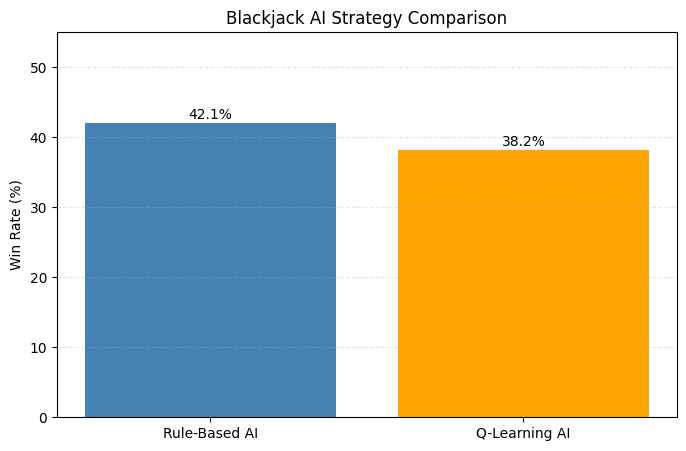

In [ ]:

# Member 2 - Basma: AI Strategy Comparison Chart
# Results from 1,000 games per strategy

import matplotlib.pyplot as plt

strategies = ["Rule-Based AI", "Q-Learning AI"]
win_rates = [
    100 * rule_results.count(1) / len(rule_results),
    100 * q_results.count(1) / len(q_results)
]

plt.figure(figsize=(8, 5))

bars = plt.bar(strategies, win_rates, color=["steelblue", "orange"])

# Display percentages above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.1f}%",
        ha="center"
    )

plt.title("Blackjack AI Strategy Comparison")
plt.ylabel("Win Rate (%)")
plt.ylim(0, 55)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.show()

## Phase 6 — Experiments, Evaluation, and Interpretation

### Objective

Compare a rule-based Blackjack AI with a Q-learning AI to evaluate how often each strategy wins against the dealer.

 ### Method

Both strategies were evaluated across 1,000 simulated games each. For each paired trial, the strategies received copies of the same shuffled starting deck. The experiment recorded wins, losses, ties, and win rate. During evaluation, the Q-learning strategy used its existing Q-table without additional training.

### Verified Comparison Results

The results below correspond to the current comparison chart in the shared notebook.

| Metric | Rule-Based AI | Q-Learning AI |
| --- | ---: | ---: |
| Games | 1,000 | 1,000 |
| Wins | 446 | 384 |
| Losses | 475 | 564 |
| Ties | 79 | 52 |
| Win rate | 44.6% | 38.4% |

Q-table states before evaluation: 135

Q-table states after evaluation: 135

The rule-based AI achieved a win rate 6.2 percentage points higher than the Q-learning AI in this experiment.

### Interpretation

Under the tested conditions, the rule-based strategy won more often than the trained Q-learning strategy (44.6% versus 38.4%). This does not establish that rule-based strategies always outperform Q-learning; rather, the Q-learning implementation did not surpass the rule-based baseline in this evaluation. The Q-table remained at 135 states before and after evaluation, consistent with a test that did not add new learned states.

### Limitations

Results can vary with training history, random card order, Q-table contents, and the number of training games. The findings apply to this project's Blackjack rules and evaluation design. One 1,000-game comparison is not enough to establish general superiority. Repeated comparisons across multiple training runs and random seeds would provide stronger evidence. The two strategies also may take different actions after receiving identical starting decks, so their subsequent game paths can diverge.

### Status and Next Steps

Basma completed the independent AI comparison, win/loss/tie calculations, win-rate chart, and documentation of findings and limitations. The documented figures match the current comparison output and chart. Integration testing of the three-hand Blackjack game has been completed successfully.  The final experimental results, win/loss/tie calculations, and AI comparison chart have been documented and validated.


In [ ]:
# Member 1: Alexander Powell
# Main entry point for the program
# Note: The main() function is defined here,
# Run the notebook cells in order before starting the game.

def main() -> None:
    deck = create_deck()
    player_hand = []
    ai_hand = []
    dealer_hand = []

    # Deal initial 2 cards to each (Player, AI, Dealer)
    for _ in range(2):
        player_hand.append(deck.pop())
        ai_hand.append(deck.pop())
        dealer_hand.append(deck.pop())

    print("--- Initial Deal ---")
    print("Player's cards:")
    print(*(f"  {c['rank']} of {c['suit']}" for c in player_hand), sep="\n")
    print(f"AI's visible card: {ai_hand[0]['rank']} of {ai_hand[0]['suit']}")
    print(f"Dealer's visible card: {dealer_hand[0]['rank']} of {dealer_hand[0]['suit']}")

    # 1. Player's turn
    print("\n--- Player's Turn ---")
    player_turn(deck=deck, player_hand=player_hand)
    player_score = calculate_score(player_hand)
    print(f"Player's final score: {player_score}")

    # 2. AI's turn (only plays if player hasn't busted)
    if player_score <= 21:
        ai_score = ai_player_turn(deck=deck, ai_hand=ai_hand, dealer_card=dealer_hand[0])
    else:
        ai_score = calculate_score(ai_hand)
    print(f"AI's final score: {ai_score}")

    # 3. Dealer's turn (only plays if at least one player hasn't busted)
    if player_score <= 21 or ai_score <= 21:
        dealer_score = dealer_turn(deck=deck, dealer_hand=dealer_hand)
    else:
        dealer_score = calculate_score(dealer_hand)
        print(f"\nDealer's final score: {dealer_score} (Dealer wins automatically as all players busted)")

    # Determine Winner using evaluate_game_winner evaluator
    print("\n--- Final Results ---")
    player_outcome = evaluate_game_winner(player_score, dealer_score)
    print(f"Player vs Dealer: {player_outcome}")

    ai_outcome = evaluate_game_winner(ai_score, dealer_score)
    print(f"AI vs Dealer: {ai_outcome}")

# Run the main function
# main()

# Member 1 — Basic Game Rules, Dealer, AI, and Main Orchestration
Contributor: Alexander

## 1. Responsibilities
Member 1 developed the underlying Blackjack game mechanics, card value rules, and orchestrated the final game loop managing three separate hands (human player, AI player, and the dealer).

## 2. Card Deck and Scoring System
- `create_deck()`: Dynamically builds and shuffles a standard 52-card deck represented as dictionary objects containing rank and suit.
- `get_card_value()`: Correctly assigns numerical values (10 for face cards, 11 for Aces, and numerical value for others).
- `calculate_score()`: Sums card values and features advanced Ace handling to dynamically downgrade Aces from 11 to 1 to prevent busting.

## 3. Dealer Strategy
- `dealer_turn()`: Automates the dealer's behavior based on classic casino rules. The dealer hits dynamically on any hand value under 17 and stands on scores of 17 or higher. Includes bust detection.
- Implemented `get_baseline_computer_action()` to act as a core strategy model, asserting "hit" on scores below 17 and "stand" on scores 17 and above.

## 4. Main Infrastructure and Orchestration
- `main()`: Orchestrates the entire game. It initializes three separate hands (human player, AI player, and dealer), manages sequential turns, and calls `evaluate_game_winner` to print the final side-by-side comparison of results against the dealer.

## 5. Deliverables and Status
- **Completed**: Card deck construction, Ace-sensitive hand calculator, dealer turn automation, baseline helper, comprehensive test suite integration, and overall three-hand main game orchestration.


# Member 2 — AI Player Development and Evaluation
Contributor: Basma

## 1. Responsibilities
Member 2 developed and evaluated AI player decision-making
functionality for the Blackjack project. The work included player
Hit/Stand/Bust logic, rule-based and Q-learning strategies, decision
tests, outcome evaluation, and experimental comparison.

## 2. Rule-Based AI Implementation
The get_ai_action_v2(ai_score, dealer_value, usable_ace) function
selects "hit" or "stand" based on the AI hand's total, the dealer's
visible card, and whether the hand contains a usable Ace. It applies
different decision rules for soft and hard hands. The rule-based AI has been successfully integrated into the main Blackjack game through ai_player_turn().  Its functionality was validated through AI decision-making tests, comprehensive testing, and successful end-to-end gameplay.  

## 3. Q-Learning Implementation
A Q-learning approach was developed to learn Hit/Stand decisions from
simulated Blackjack games. It uses a Q-table, state representation,
rewards derived from outcomes, and repeated training episodes.
Performance depends on state design, reward definition, exploration
and training settings.

## 4. Game Outcome Evaluation
The `evaluate_game_winner(player_score, dealer_score)` function determines the game outcome as "Win", "Loss", or "Tie" by checking whether the player busts, the dealer busts, or which score is higher.

All five initial functional tests passed successfully.

Additional end-to-end gameplay testing confirmed that the human player, rule-based AI player, and dealer operate together and that the game correctly evaluates and displays the final outcomes.

The comprehensive tests passed, and the notebook completed a fresh-session execution without errors.

**Integration Status: COMPLETE.**

## 5. Experimental Evaluation
The rule-based AI and Q-learning AI strategies were evaluated using 1,000 simulated Blackjack games per strategy.

For a fair comparison, both strategies were evaluated using matched shuffled starting decks. Q-learning training was completed before evaluation, and no additional training occurred during testing.

### Final Experimental Results

| Metric | Rule-Based AI | Q-Learning AI |
|---|---:|---:|
| Games Played | 1,000 | 1,000 |
| Wins | 446 | 384 |
| Losses | 475 | 564 |
| Ties | 79 | 52 |
| Win Rate | 44.6% | 38.4% |

### Results Summary

The rule-based AI achieved a 44.6% win rate, compared with 38.4% for Q-learning.

The observed difference was 6.2 percentage points in favor of the rule-based strategy.

The Q-learning evaluation was performed independently of the integrated main game. The main game uses the rule-based strategy through `get_ai_action_v2()`.

The Q-table contained 135 states before and after evaluation, confirming that the evaluation did not add new states.

## 6. Results and Interpretation
Under the tested conditions, rule-based AI achieved a higher observed
win rate than Q-learning. This result does not establish universal
superiority: Q-learning performance may change with additional
training, a different state representation, rewards, or
hyperparameters. The results should be reported as observed outcomes
of this experiment, not as proof that the trained AI is stronger.

## 7. Project Limitations
- The rule-based AI has been successfully integrated into the main Blackjack game and validated through functional and end-to-end testing.
- The Q-learning strategy has been trained and evaluated independently but is not selectable in the integrated main game.
- Additional training runs, random seeds, and experimental replications would strengthen confidence in the comparison results.
- The current outcome evaluator compares final scores and bust conditions.
- Additional Blackjack rules, such as natural-blackjack payouts, splits, doubles, and dealer soft-17 rules, would require explicit implementation and testing if included in the project scope.


## 8. Member 2 Deliverables and Status
### Completed Deliverables

- Human player Hit, Stand, and Bust functionality.
- Rule-based AI decision-making using `get_ai_action_v2()`.
- AI player gameplay using `ai_player_turn()`.
- Q-learning implementation, training, and evaluation.
- Game-outcome evaluation with five successful tests.
- AI decision-making and gameplay tests.
- Integration of the rule-based AI into the main Blackjack game.
- Successful end-to-end gameplay testing involving the human player, AI player, and dealer.
- Comprehensive testing: PASS.
- Fresh-session notebook execution: PASS.
- Experimental comparison of 1,000 games per AI strategy.
- Final comparison results: Rule-Based AI 44.6% versus Q-Learning AI 38.4%.
- Comparison chart and experimental interpretation.
- Phase 7 documentation updates.

### Current Status

**Member 2 development, testing, and experimental evaluation: COMPLETE.**

The integrated Blackjack game has been successfully tested. The human player, rule-based AI player, and dealer completed gameplay, and the game correctly determined the outcomes.

The Q-learning strategy was independently trained and evaluated against the rule-based strategy. It is not currently used by the main game's AI player.

Alexander has confirmed completion of his assigned development and testing responsibilities through Phase 6.


## 9. Conclusion
Member 2 successfully developed, implemented, and evaluated two AI decision-making strategies for the Blackjack project: rule-based AI and Q-learning.

The final experimental evaluation included 1,000 simulated games per strategy. The rule-based AI achieved 446 wins (44.6%), while Q-learning achieved 384 wins (38.4%). The rule-based strategy demonstrated a 6.2 percentage-point higher win rate under the tested conditions.

The rule-based AI was successfully integrated into the main Blackjack game. Functional testing, comprehensive testing, and end-to-end gameplay validation were completed successfully.

The Q-learning strategy was independently trained and evaluated but was not integrated as a selectable strategy in the main game.

Overall, the project demonstrates the implementation, testing, and comparison of two AI approaches to Blackjack decision-making. The findings highlight the effectiveness of the rule-based strategy under the evaluated conditions while identifying opportunities for further experimentation with Q-learning.

In [ ]:
main()

--- Initial Deal ---
Player's cards:
  2 of Clubs
  Jack of Spades
AI's visible card: 7 of Hearts
Dealer's visible card: 9 of Spades

--- Player's Turn ---
Player's current score: 12
Would you like to Hit or Stand? hit
You drew: King of Hearts
Player's current score: 22
Player busts!
Player's final score: 22
AI's final score: 13

--- Dealer's Turn ---
Dealer's current cards:
  9 of Spades
  Jack of Diamonds
Dealer's current score: 19
Dealer stands.

--- Final Results ---
Player vs Dealer: Loss
AI vs Dealer: Loss
